# Analyse exploratoire des données (EDA) DPE Hauts-de-France

**Plan :**
1. Chargement & vue d'ensemble
2. Analyse de la variable cible
3. Analyse des valeurs manquantes
4. Analyse des variables quantitatives (distribution, outliers, corrélations)
5. Analyse des variables qualitatives (cardinalité, vue d'ensemble)
6. Relation entre variables et cible
7. Synthèse — ce que l'EDA révèle pour le preprocessing

## 1. Chargement & vue d'ensemble

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 100})

df_raw = pd.read_csv('../data/dpe_hauts_de_france_2025-07-01_to_2025-12-31_half.csv', sep=',')

print(f"Dataset brut : {df_raw.shape[0]:,} lignes × {df_raw.shape[1]} colonnes")
df_raw.head()

Dataset brut : 57,826 lignes × 46 colonnes


,etiquette_dpe,numero_dpe,date_etablissement_dpe,code_region_ban,code_departement_ban,code_postal_ban,code_insee_ban,nom_commune_ban,zone_climatique,classe_altitude,...,configuration_installation_ecs_n1,type_generateur_n1_ecs_n1,type_generateur_chauffage_principal_ecs,type_energie_principale_ecs,type_energie_generateur_n1_ecs_n1,usage_generateur_n1_ecs_n1,volume_stockage_generateur_n1_ecs_n1,ventilation_posterieure_2012,type_installation_solaire_n1,production_electricite_pv_kwhep_par_an
0,C,2559E3504406H,2025-11-05,32,59,59320,59286,Haubourdin,H1a,inférieur à 400m,...,Un seul système d'ECS sans solaire,Chaudière gaz à condensation après 2015,Chaudière gaz à condensation après 2015,Gaz naturel,Gaz naturel,chauffage + ecs,0.0,1,Non affecté,0.0
1,F,2559E2432688J,2025-07-24,32,59,59360,59136,Le Cateau-Cambrésis,H1a,inférieur à 400m,...,Un seul système d'ECS sans solaire,Chaudière gaz à condensation 2001-2015,NaN,Gaz naturel,Gaz naturel,chauffage + ecs,0.0,0,Non affecté,0.0
2,C,2502E3087497D,2025-09-30,32,2,2170,2558,Le Nouvion-en-Thiérache,H1a,inférieur à 400m,...,Un seul système d'ECS sans solaire,CET sur air ambiant (sur local non chauffé) ap...,NaN,Électricité,Électricité,ecs,150.0,1,Non affecté,0.0
3,E,2502E3013330O,2025-09-23,32,2,2000,2408,Laon,H1a,inférieur à 400m,...,Un seul système d'ECS sans solaire,Ballon électrique à accumulation vertical Caté...,NaN,Électricité,Électricité,ecs,150.0,0,Non affecté,0.0
4,C,2562E2831514Y,2025-09-08,32,62,62180,62688,Rang-du-Fliers,H1a,inférieur à 400m,...,Un seul système d'ECS sans solaire,Chaudière gaz à condensation après 2015,Chaudière gaz à condensation après 2015,Gaz naturel,Gaz naturel,chauffage + ecs,0.0,0,Non affecté,0.0


In [15]:
# Vue d'ensemble : type, complétude, cardinalité
overview = pd.DataFrame({
    'dtype'        : df_raw.dtypes.astype(str),
    'non_null'     : df_raw.notnull().sum(),
    'pct_missing'  : (df_raw.isnull().sum() / len(df_raw) * 100).round(1),
    'n_unique'     : df_raw.nunique(),
}).sort_values('pct_missing', ascending=False)

overview

,dtype,non_null,pct_missing,n_unique
nombre_niveau_immeuble,float64,13638,76.4,19
surface_habitable_immeuble,float64,18237,68.5,3858
type_generateur_chauffage_principal_ecs,str,18651,67.7,73
type_generateur_chauffage_principal,str,18696,67.7,93
qualite_isolation_plancher_haut_comble_perdu,str,27260,52.9,4
annee_construction,float64,27798,51.9,204
nombre_appartement,float64,28386,50.9,135
type_installation_ecs,str,30213,47.8,3
type_installation_chauffage,str,30213,47.8,3
numero_etage_appartement,float64,51558,10.8,19


## 2. Analyse de la variable cible — `etiquette_dpe`

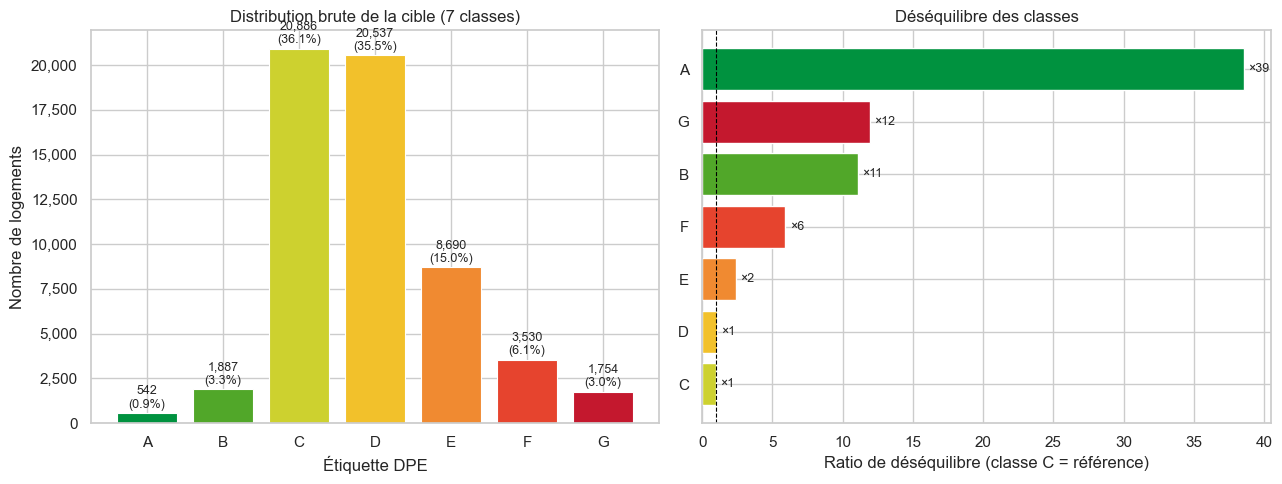

Résumé :
  Classe majoritaire : C (20,886 — 36.1%)
  Classe minoritaire : A (542 — 0.9%)
  Ratio max/min      : 39:1


In [3]:
DPE_ORDER  = ['A', 'B', 'C', 'D', 'E', 'F', 'G']
DPE_COLORS = {
    'A': '#00923F', 'B': '#51A729', 'C': '#CDD12F',
    'D': '#F2C12B', 'E': '#F08A31', 'F': '#E6442E', 'G': '#C4182E'
}

vc = df_raw['etiquette_dpe'].value_counts().reindex(DPE_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bar_colors = [DPE_COLORS[c] for c in vc.index]
bars = axes[0].bar(vc.index, vc.values, color=bar_colors, edgecolor='white', linewidth=0.8)
for bar, (label, count) in zip(bars, vc.items()):
    pct = count / len(df_raw) * 100
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 150,
                 f'{count:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=9)
axes[0].set_xlabel("Étiquette DPE")
axes[0].set_ylabel("Nombre de logements")
axes[0].set_title("Distribution brute de la cible (7 classes)")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x):,}'))

max_class = vc.max()
ratios = (max_class / vc).sort_values()
axes[1].barh(ratios.index, ratios.values, color=[DPE_COLORS[c] for c in ratios.index])
axes[1].axvline(1, color='black', linewidth=0.8, linestyle='--')
for i, (label, ratio) in enumerate(ratios.items()):
    axes[1].text(ratio + 0.3, i, f'×{ratio:.0f}', va='center', fontsize=9)
axes[1].set_xlabel("Ratio de déséquilibre (classe C = référence)")
axes[1].set_title("Déséquilibre des classes")

plt.tight_layout()
plt.show()

print("Résumé :")
print(f"  Classe majoritaire : C ({vc['C']:,} — {vc['C']/len(df_raw)*100:.1f}%)")
print(f"  Classe minoritaire : A ({vc['A']:,} — {vc['A']/len(df_raw)*100:.1f}%)")
print(f"  Ratio max/min      : {vc.max()/vc.min():.0f}:1")

#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>
Le jeu de données est **fortement déséquilibré**. La classe A représente moins de 1% des observations contre 36% pour C, soit un ratio de 38:1. Cette observation, faite ici sur les données brutes, est ce qui motivera plus loin (dans le preprocessing) le regroupement en 3 super-classes (`Performant`/`Passable`/`Energivore`) : un déséquilibre aussi extrême sur 7 classes rendrait la classification très instable, alors qu'un regroupement cohérent avec la réglementation thermique réduit le problème tout en restant interprétable pour un usage métier.

## 3. Analyse des valeurs manquantes

### 3.1 Heatmap des valeurs manquantes

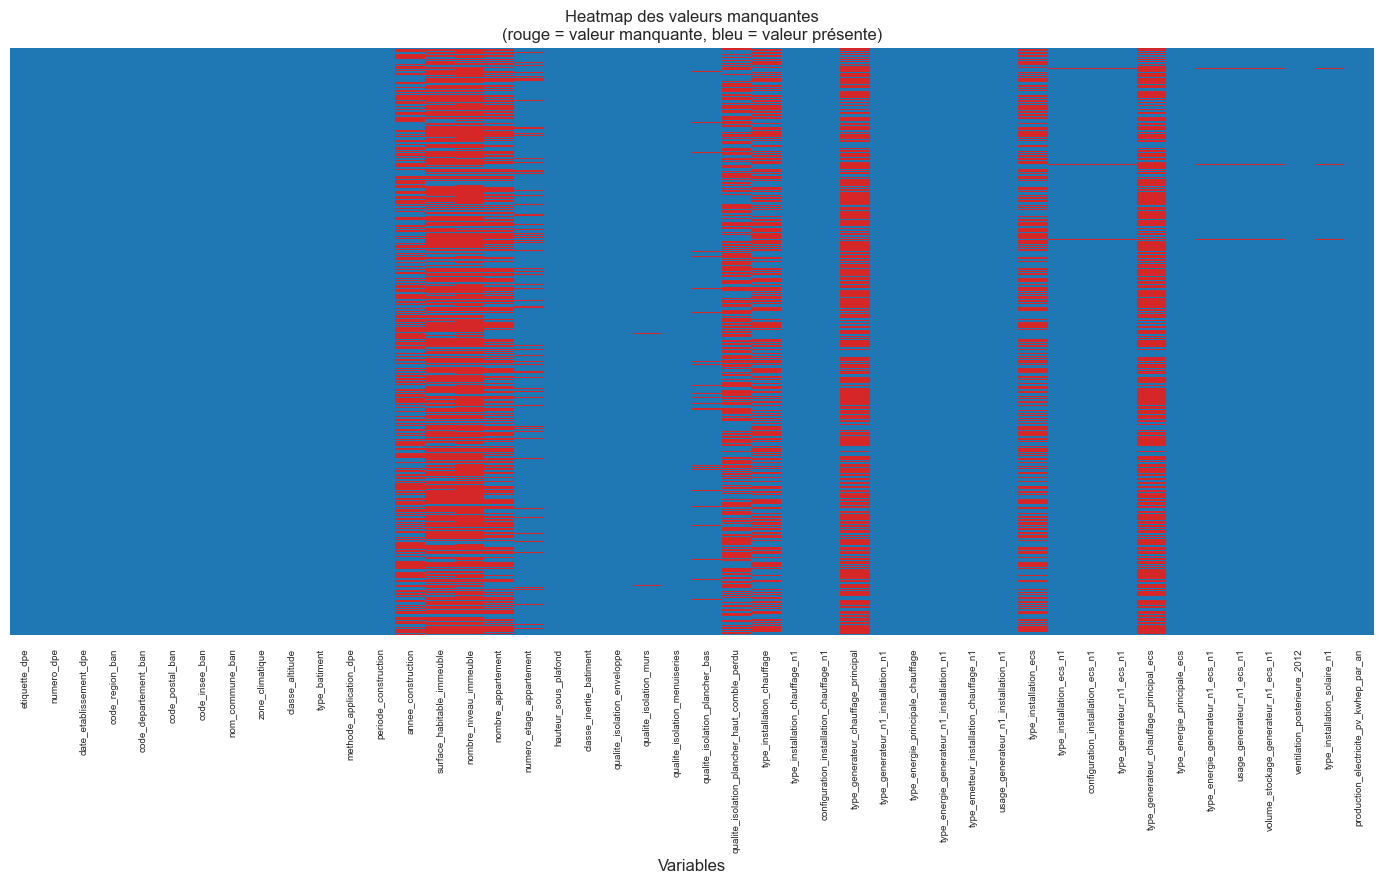

In [4]:
fig, ax = plt.subplots(figsize=(14, 9))
sns.heatmap(df_raw.isnull(), cbar=False, cmap=['#1f77b4', '#d62728'], ax=ax,
            yticklabels=False)
ax.set_title("Heatmap des valeurs manquantes\n(rouge = valeur manquante, bleu = valeur présente)")
ax.set_xlabel("Variables")
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

### 3.2 Pourcentage de valeurs manquantes par variable

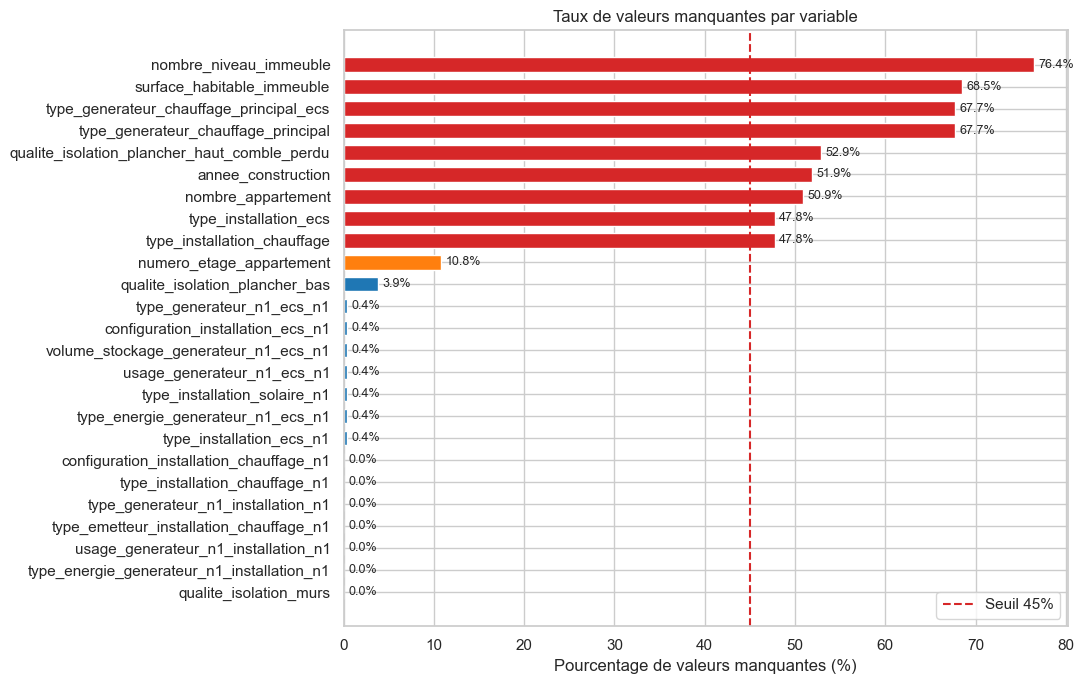

In [5]:
missing = (
    df_raw.isnull().sum()
    .reset_index()
    .rename(columns={'index': 'variable', 0: 'counts'})
)
missing['percent'] = (missing['counts'] / len(df_raw)) * 100
missing = missing[missing['counts'] > 0].sort_values('percent', ascending=True)

fig, ax = plt.subplots(figsize=(11, 7))
colors = ['#d62728' if p > 45 else '#ff7f0e' if p > 10 else '#1f77b4' for p in missing['percent']]
bars = ax.barh(missing['variable'], missing['percent'], color=colors, height=0.65)
ax.axvline(45, color='#d62728', linestyle='--', linewidth=1.5, label='Seuil 45%')
for bar, pct in zip(bars, missing['percent']):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{pct:.1f}%', va='center', ha='left', fontsize=9)
ax.set_xlabel("Pourcentage de valeurs manquantes (%)")
ax.set_title("Taux de valeurs manquantes par variable")
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>
Les variables dépassant 45% de valeurs manquantes (en rouge) seront candidates à la suppression dans le preprocessing — au-delà de ce seuil, l'imputation introduirait plus de bruit que de signal réel. Les variables entre 10% et 45% (orange) restent exploitables avec une imputation prudente. Celles sous 10% (bleu) ont un impact minime même en cas de suppression de lignes.

### 3.3 Test : les valeurs manquantes sont-elles liées à la cible ?

In [21]:
# Test MNAR : si l'absence d'une valeur est statistiquement liée à la classe DPE, alors les valeurs manquantes ne sont pas aléatoires 
cols_with_missing = missing['variable'].tolist()

print("Test du Chi² — Présence/absence de la valeur vs classe DPE\n")
print(f"{'Variable':<55} {'p-value':>10} {'Lié à la cible ?':>18}")
print("─" * 86)

for col in cols_with_missing:
    mask_nan = df_raw[col].isnull()
    if mask_nan.sum() < 10:
        continue
    ct = pd.crosstab(mask_nan, df_raw['etiquette_dpe'])
    if ct.shape[0] < 2:
        continue
    try:
        chi2, p, _, _ = chi2_contingency(ct)
        lien = " OUI (p<0.05)" if p < 0.05 else "non"
        print(f"{col:<55} {p:>10.4f} {lien:>18}")
    except Exception:
        pass

Test du Chi² — Présence/absence de la valeur vs classe DPE

Variable                                                   p-value   Lié à la cible ?
──────────────────────────────────────────────────────────────────────────────────────
qualite_isolation_murs                                      0.0022       OUI (p<0.05)
type_energie_generateur_n1_installation_n1                  0.0000       OUI (p<0.05)
usage_generateur_n1_installation_n1                         0.0000       OUI (p<0.05)
type_emetteur_installation_chauffage_n1                     0.0000       OUI (p<0.05)
type_generateur_n1_installation_n1                          0.0000       OUI (p<0.05)
type_installation_chauffage_n1                              0.0000       OUI (p<0.05)
configuration_installation_chauffage_n1                     0.0000       OUI (p<0.05)
type_installation_ecs_n1                                    0.0000       OUI (p<0.05)
type_energie_generateur_n1_ecs_n1                           0.0000       OUI (p

#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>
Toutes les variables testées sont liées à la classe DPE (p < 0.05), les valeurs manquantes ne sont pas aléatoires (MNAR). Une suppression de lignes biaiserait l'échantillon vers les logements les mieux documentés. Cela justifie le traitement différencié retenu : suppression des colonnes structurellement incomplètes, imputation prudente pour le reste.

## 4. Analyse des variables quantitatives

In [7]:
quant_cols = [
    "hauteur_sous_plafond",
    "volume_stockage_generateur_n1_ecs_n1",
    "ventilation_posterieure_2012",
    "production_electricite_pv_kwhep_par_an",
]
quant_cols = [c for c in quant_cols if c in df_raw.columns]

df_raw[quant_cols].describe().round(2)

,hauteur_sous_plafond,volume_stockage_generateur_n1_ecs_n1,ventilation_posterieure_2012,production_electricite_pv_kwhep_par_an
count,57826.00,57599.00,57826.00,57826.00
mean,2.56,93.85,0.37,42.72
std,1.73,228.66,0.48,1980.19
min,1.00,0.00,0.00,0.00
25%,2.50,0.00,0.00,0.00
50%,2.50,0.00,0.00,0.00
75%,2.50,150.00,1.00,0.00
max,240.00,10000.00,1.00,460380.80


#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

La `hauteur_sous_plafond` affiche un maximum de 240m alors que sa médiane est à 2.50m — une valeur physiquement impossible pour un logement, révélant des erreurs de saisie à corriger par capping. `volume_stockage_generateur_n1_ecs_n1` et `production_electricite_pv_kwhep_par_an` ont une médiane à 0 mais un maximum élevé (10 000 et 460 380), confirmant une distribution dominée par des zéros avec quelques valeurs extrêmes : ces logements ne sont simplement pas équipés (pas de stockage ECS, pas de panneaux solaires), ce qui justifie la transformation `log1p` plutôt qu'une suppression. `ventilation_posterieure_2012` est une variable binaire (0/1), cohérente avec son nom.

### 4.1 Détection visuelle des outliers — boxplots

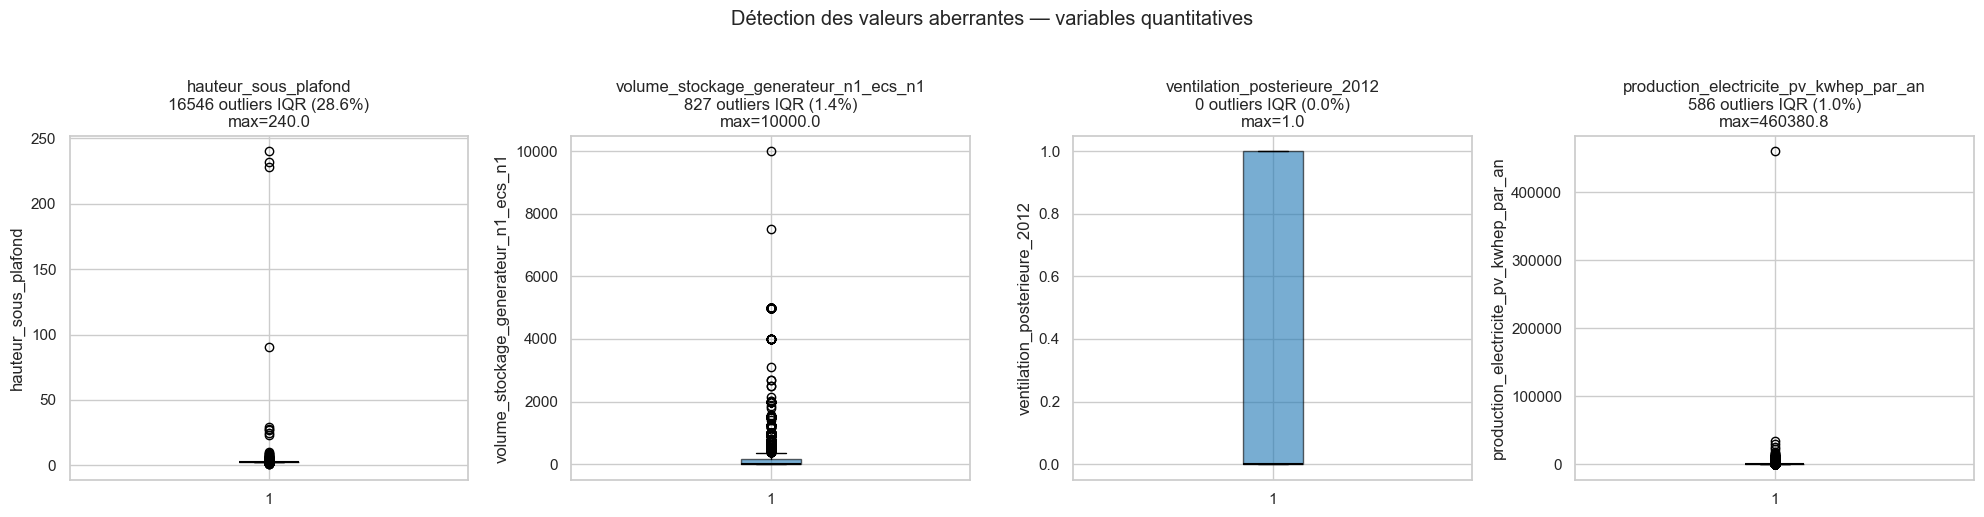

In [22]:
fig, axes = plt.subplots(1, len(quant_cols), figsize=(5 * len(quant_cols), 5))
if len(quant_cols) == 1:
    axes = [axes]

for ax, col in zip(axes, quant_cols):
    data_col = df_raw[col].dropna()
    bp = ax.boxplot(data_col, vert=True, patch_artist=True,
                     medianprops=dict(color='black', linewidth=1.5))
    bp['boxes'][0].set_facecolor('#1f77b4')
    bp['boxes'][0].set_alpha(0.6)

    q1, q3 = data_col.quantile([0.25, 0.75])
    iqr = q3 - q1
    out_low, out_high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((data_col < out_low) | (data_col > out_high)).sum()

    ax.set_title(f'{col}\n{n_outliers} outliers IQR ({n_outliers/len(data_col)*100:.1f}%)\nmax={data_col.max():.1f}')
    ax.set_ylabel(col)

plt.suptitle("Détection des valeurs aberrantes — variables quantitatives", y=1.03)
plt.tight_layout()
plt.show()

#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Les boxplots confirment et quantifient l'anomalie repérée sur `hauteur_sous_plafond` : avec **28.6% d'outliers IQR**, un taux anormalement élevé, le maximum de 240m n'est pas un cas isolé mais une erreur de saisie systémique (probablement une confusion d'unité ou de champ) — le capping à une borne physiquement raisonnable est indispensable. `volume_stockage_generateur_n1_ecs_n1` (1.4%) et `production_electricite_pv_kwhep_par_an` (1.0%) affichent des taux d'outliers beaucoup plus faibles : leurs valeurs extrêmes correspondent à de vrais équipements de forte capacité plutôt qu'à des erreurs, ce qui justifie une transformation `log1p` qui les compresse sans les supprimer. `ventilation_posterieure_2012`, variable binaire, n'a logiquement aucun outlier (0.0%).

### 4.2 Distribution détaillée et asymétrie

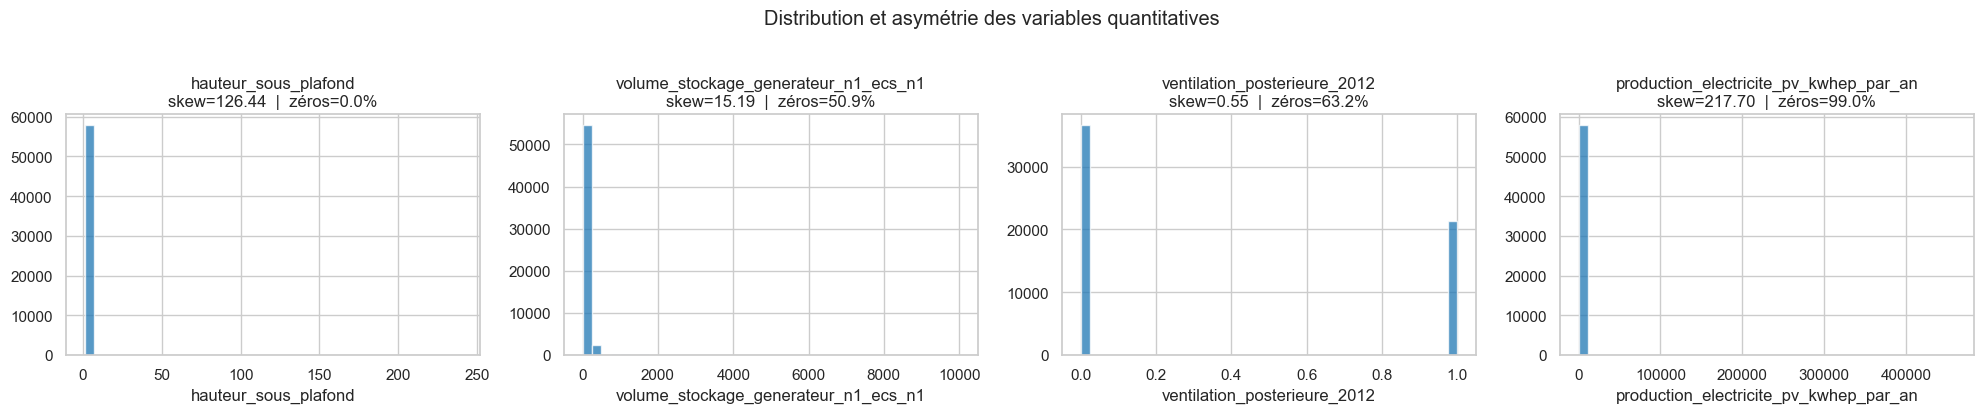

In [23]:
fig, axes = plt.subplots(1, len(quant_cols), figsize=(5 * len(quant_cols), 4))
if len(quant_cols) == 1:
    axes = [axes]

for ax, col in zip(axes, quant_cols):
    data_col = df_raw[col].dropna()
    ax.hist(data_col, bins=40, color='#1f77b4', alpha=0.75, edgecolor='white')
    skew = data_col.skew()
    pct_zero = (data_col == 0).mean() * 100
    ax.set_title(f'{col}\nskew={skew:.2f}  |  zéros={pct_zero:.1f}%')
    ax.set_xlabel(col)

plt.suptitle("Distribution et asymétrie des variables quantitatives", y=1.03)
plt.tight_layout()
plt.show()

#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Nous constatons un skewness extrême pour `hauteur_sous_plafond` (126.44) et `production_electricite_pv_kwhep_par_an` (217.70), confirmant la présence d'erreurs de saisie et de valeurs très concentrées sur quelques observations rares. `production_electricite_pv_kwhep_par_an` présente **99.0% de zéros** : seuls les logements équipés de panneaux solaires ont une valeur non nulle, ce qui justifie pleinement la transformation `log1p` plutôt qu'une normalisation classique, qui serait écrasée par cette masse de zéros. `volume_stockage_generateur_n1_ecs_n1` suit la même logique avec 50.9% de zéros et un skew de 15.19. `ventilation_posterieure_2012`, avec un skew modéré (0.55) et 63.2% de zéros, reste une variable binaire cohérente ne nécessitant aucune transformation.

### 4.3 Variables quantitatives selon la classe DPE

C:\Users\berul\AppData\Local\Temp\ipykernel_19040\3832892277.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(grouped, labels=valid_classes, patch_artist=True,
C:\Users\berul\AppData\Local\Temp\ipykernel_19040\3832892277.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(grouped, labels=valid_classes, patch_artist=True,
C:\Users\berul\AppData\Local\Temp\ipykernel_19040\3832892277.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(grouped, labels=valid_classes, patch_artist=True,
C:\Users\berul\AppData\Local\Temp\ipykernel_19040\3832892277.py:12: MatplotlibDepreca

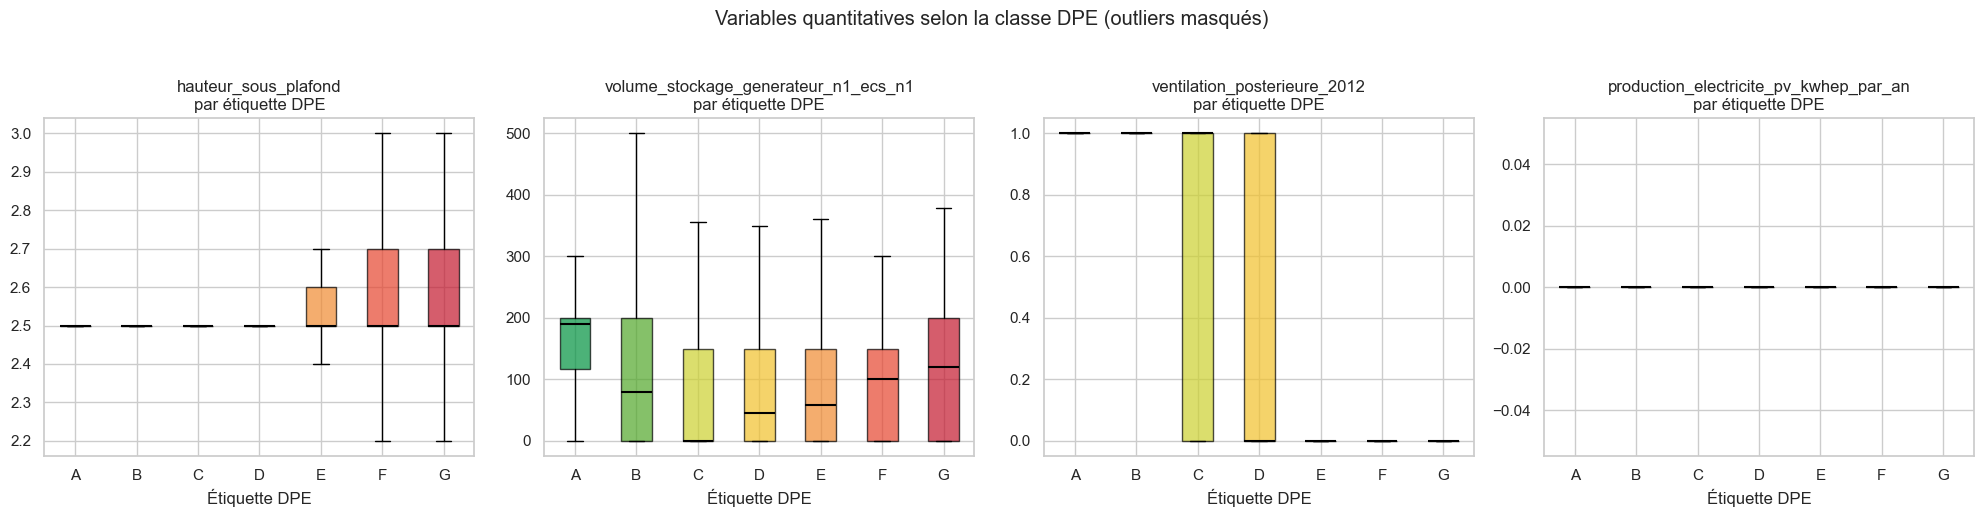

In [24]:
fig, axes = plt.subplots(1, len(quant_cols), figsize=(5 * len(quant_cols), 5))
if len(quant_cols) == 1:
    axes = [axes]

for ax, col in zip(axes, quant_cols):
    data_plot = df_raw[[col, 'etiquette_dpe']].dropna()
    data_plot = data_plot[data_plot['etiquette_dpe'].isin(DPE_ORDER)]
    grouped = [data_plot[data_plot['etiquette_dpe'] == cls][col].values for cls in DPE_ORDER
               if len(data_plot[data_plot['etiquette_dpe'] == cls]) > 0]
    valid_classes = [cls for cls in DPE_ORDER if len(data_plot[data_plot['etiquette_dpe'] == cls]) > 0]

    bp = ax.boxplot(grouped, labels=valid_classes, patch_artist=True,
                     medianprops=dict(color='black', linewidth=1.5), showfliers=False)
    for patch, cls in zip(bp['boxes'], valid_classes):
        patch.set_facecolor(DPE_COLORS.get(cls, '#999'))
        patch.set_alpha(0.7)
    ax.set_title(f'{col}\npar étiquette DPE')
    ax.set_xlabel('Étiquette DPE')

plt.suptitle("Variables quantitatives selon la classe DPE (outliers masqués)", y=1.03)
plt.tight_layout()
plt.show()

#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Nous constatons que `hauteur_sous_plafond` et `volume_stockage_generateur_n1_ecs_n1` ont un pouvoir discriminant réel sur la classe DPE, avec une tendance décroissante des logements performants vers les énergivores. `production_electricite_pv_kwhep_par_an`, quasi nulle partout, n'apporte ici aucun signal visible (masqué par les 99% de zéros).

### 4.4 Matrice de corrélation des variables quantitatives

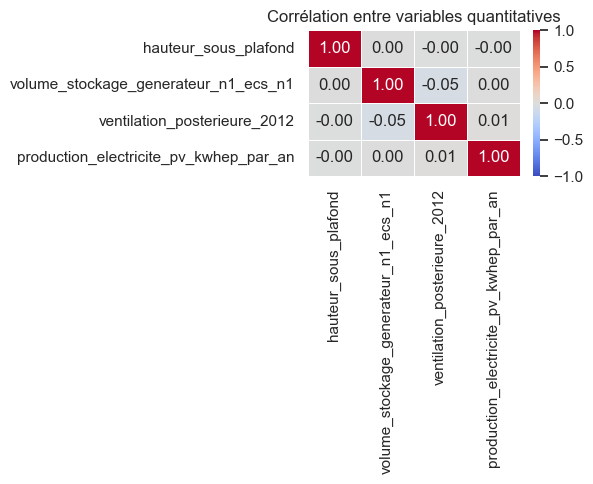

In [25]:
corr = df_raw[quant_cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, ax=ax, linewidths=0.5)
ax.set_title("Corrélation entre variables quantitatives")
plt.tight_layout()
plt.show()

#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Nous constatons des corrélations toutes proches de zéro entre les variables quantitatives, confirmant qu'elles mesurent des aspects physiquement indépendants du logement, sans redondance d'information à traiter.

## 5. Analyse des variables qualitatives — vue d'ensemble

In [18]:
qual_cols = [c for c in df_raw.columns if c not in quant_cols + ['etiquette_dpe']]
qual_cols = [c for c in qual_cols if df_raw[c].dtype == 'str']

card_table = pd.DataFrame({
    'n_modalites'  : [df_raw[c].nunique() for c in qual_cols],
    'pct_mode'     : [df_raw[c].value_counts(normalize=True).iloc[0] * 100 for c in qual_cols],
    'modalite_top' : [df_raw[c].value_counts().index[0] for c in qual_cols],
}, index=qual_cols).sort_values('n_modalites', ascending=False)

card_table

,n_modalites,pct_mode,modalite_top
numero_dpe,57826,0.001729,2559E3504406H
nom_commune_ban,2809,6.683845,Lille
date_etablissement_dpe,183,1.284889,2025-09-29
type_generateur_n1_installation_n1,132,26.842561,Chaudière gaz à condensation après 2015
type_generateur_n1_ecs_n1,95,25.127172,Ballon électrique à accumulation vertical Caté...
type_generateur_chauffage_principal,93,29.482242,Chaudière gaz à condensation après 2015
type_generateur_chauffage_principal_ecs,73,26.861830,Chaudière gaz à condensation après 2015
type_emetteur_installation_chauffage_n1,46,24.937716,Radiateur bitube avec robinet thermostatique s...
type_energie_principale_ecs,12,48.619998,Gaz naturel
type_energie_principale_chauffage,11,53.583163,Gaz naturel


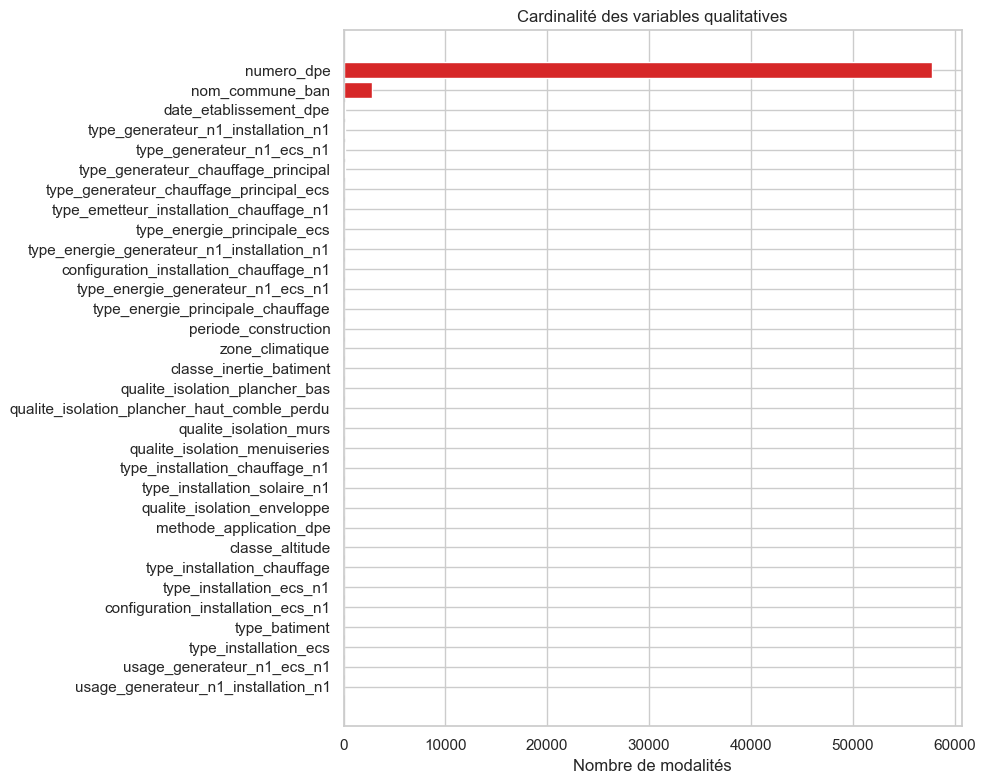

In [19]:
# Visualisation des cardinalités
fig, ax = plt.subplots(figsize=(10, 8))
card_sorted = card_table.sort_values('n_modalites')
colors_card = ['#d62728' if n > 30 else '#ff7f0e' if n > 10 else '#1f77b4'
               for n in card_sorted['n_modalites']]
ax.barh(card_sorted.index, card_sorted['n_modalites'], color=colors_card)
ax.set_xlabel("Nombre de modalités")
ax.set_title("Cardinalité des variables qualitatives")
plt.tight_layout()
plt.show()

## 6. Relation entre variables qualitatives et la cible

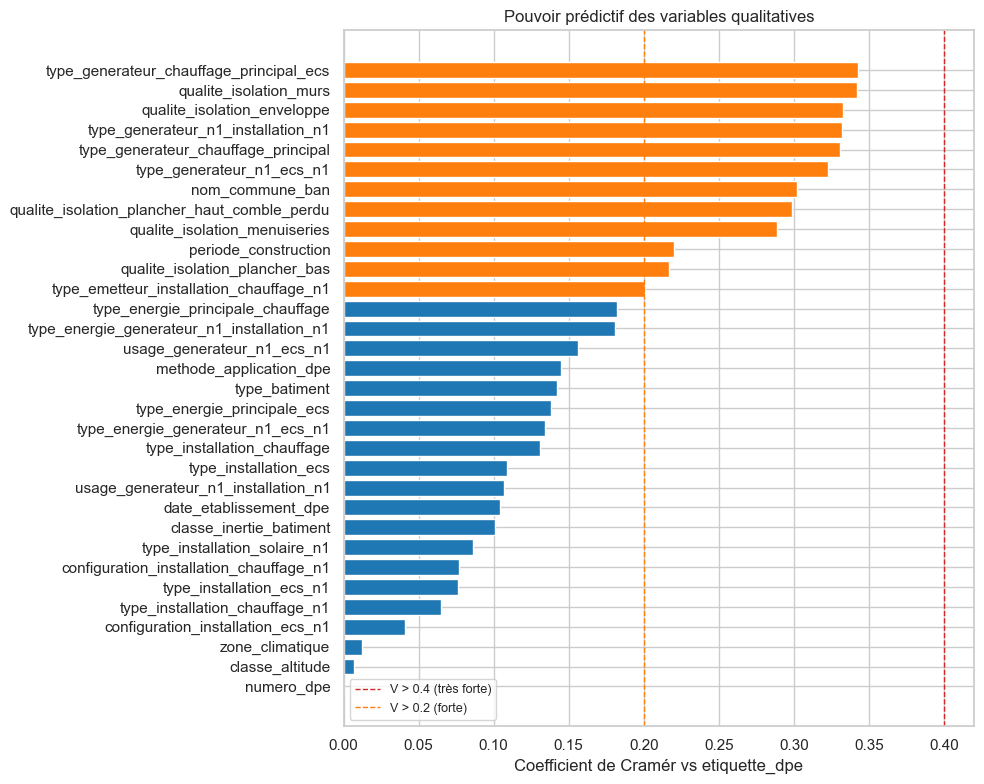

In [27]:
def cramers_v(x, y):
    
    '''
    Cette fonction calcule le coefficient de Cramér entre deux variables catégorielles,
    mesurant la force de leur association (0 = aucun lien, 1 = lien parfait)
    '''
    ct = pd.crosstab(x, y)
    chi2, _, _, _ = chi2_contingency(ct)
    n = ct.sum().sum()
    r, k = ct.shape
    phi2 = chi2 / n
    phi2_corr = max(0, phi2 - (k-1)*(r-1)/(n-1))
    r_corr = r - (r-1)**2/(n-1)
    k_corr = k - (k-1)**2/(n-1)
    denom = min(k_corr - 1, r_corr - 1)
    return np.sqrt(phi2_corr / denom) if denom > 0 else 0.0

target_assoc = []
for col in qual_cols:
    v = cramers_v(df_raw[col].astype(str), df_raw['etiquette_dpe'].astype(str))
    target_assoc.append({'variable': col, 'cramers_v': round(v, 3)})

target_assoc_df = pd.DataFrame(target_assoc).sort_values('cramers_v', ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
sorted_assoc = target_assoc_df.sort_values('cramers_v')
colors_v = ['#d62728' if v >= 0.4 else '#ff7f0e' if v >= 0.2 else '#1f77b4'
            for v in sorted_assoc['cramers_v']]
ax.barh(sorted_assoc['variable'], sorted_assoc['cramers_v'], color=colors_v)
ax.axvline(0.4, color='#d62728', linestyle='--', linewidth=1, label='V > 0.4 (très forte)')
ax.axvline(0.2, color='#ff7f0e', linestyle='--', linewidth=1, label='V > 0.2 (forte)')
ax.set_xlabel("Coefficient de Cramér vs etiquette_dpe")
ax.set_title("Pouvoir prédictif des variables qualitatives")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Nous constatons que le type de générateur de chauffage et la qualité d'isolation portent le plus fort pouvoir discriminant sur la classe DPE (V proche de 0.35), confirmant leur rôle central attendu dans la performance énergétique. À l'inverse, `zone_climatique`, `classe_altitude` et `numero_dpe` n'apportent quasiment aucun signal et seront candidates à la suppression.

## 7. Synthèse — ce que l'EDA révèle pour le preprocessing

| Observation EDA | Décision de preprocessing qui en découle |
|---|---|
| Déséquilibre extrême de la cible (38:1) | Regroupement en 3 super-classes (`Performant`/`Passable`/`Energivore`) |
| Variables avec >45% de manquants | Suppression de ces colonnes |
| Manquants liés à la cible (test du Chi²) | Choix d'une stratégie d'imputation prudente plutôt qu'une suppression aveugle |
| `hauteur_sous_plafond` avec outliers extrêmes | Capping à 6m (erreurs de saisie identifiées visuellement) |
| Forte proportion de zéros et asymétrie sur 2 variables | Transformation `log1p` |
| Variables quasi-constantes (>95% une seule modalité) | Suppression (`suppress_quasi_const`) |
| Variables à très haute cardinalité (>30 modalités) | Regroupement des modalités rares |
| Coefficient de Cramér élevé sur isolation et énergie | Conservation prioritaire de ces variables, vigilance sur leur encodage |

Le notebook suivant (`preprocessing_final.ipynb`) applique ces décisions, chacune étant désormais justifiée par une observation faite ici plutôt que par une intuition. Il pousse également l'analyse des variables catégorielles plus en profondeur, en recherchant les paires fortement corrélées entre elles afin d'identifier les redondances à éliminer, puis en regroupant les modalités proches par agrégation pour réduire la cardinalité tout en conservant le pouvoir discriminant sur la cible. Au total, ce notebook réalise : l'encodage de la cible en 3 classes, le nettoyage des colonnes non pertinentes et quasi-constantes, le traitement des valeurs manquantes et des outliers, la détection et suppression des variables catégorielles redondantes, l'agrégation des modalités à forte cardinalité via clustering hiérarchique, et l'encodage ordinal des variables ayant un ordre naturel.